### Evaluation Metrics for Classification

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

#### Data Preparation

***Data is from the 2026 lead-scoring dataset for classification***

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [4]:
#checking missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
#checking data types
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
#fixing missing values

missing_str = list(df.dtypes[df.dtypes == 'str'].index)
missing_float = list(df.dtypes[df.dtypes == 'float64'].index)

for col in missing_str:
    df[col] = df[col].fillna("NA")

for col in missing_float:
    df[col] = df[col].fillna("0.0")

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [7]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [8]:
#splitting the dataset

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [9]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [10]:
#This is necessary for use in getting a subset of data from a 'boolean condition' rather than an object
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score',] #note that the target variable is not included
features = categorical + numerical

### Question 1

***Evaluating feature importance of numerical variables using ROC AUC***

In [11]:
from sklearn.metrics import roc_auc_score

scores = {}

for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])

    scores[col] = auc

sorted(scores.items(), key=lambda x: x[1], reverse=True)

[('lead_score', 0.7882254810906102),
 ('interaction_count', 0.7649203047563227),
 ('number_of_courses_viewed', 0.7229894623989618),
 ('annual_income', 0.6081977776250831)]

### Question 2

***Training the model***

In [12]:
# Convert dataframes to dictionaries
train_dict = df_train[features].to_dict(orient='records')
val_dict = df_val[features].to_dict(orient='records')

In [13]:
# One-hot encoding
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

In [14]:
# Train logistic regression
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [15]:
# Predict probabilities
y_pred = model.predict_proba(X_val)[:, 1]

In [16]:
# Compute AUC
auc = roc_auc_score(y_val, y_pred)

print(round(auc, 3))

0.731


### Question 3

***Precision and Recall***

In [17]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.01, 0.01)

scores = []

for t in thresholds:
    y_pred_t = (y_pred >= t).astype(int)

    p = precision_score(y_val, y_pred_t, zero_division=0)
    r = recall_score(y_val, y_pred_t, zero_division=0)

    scores.append((t, p, r))

***Plotting***

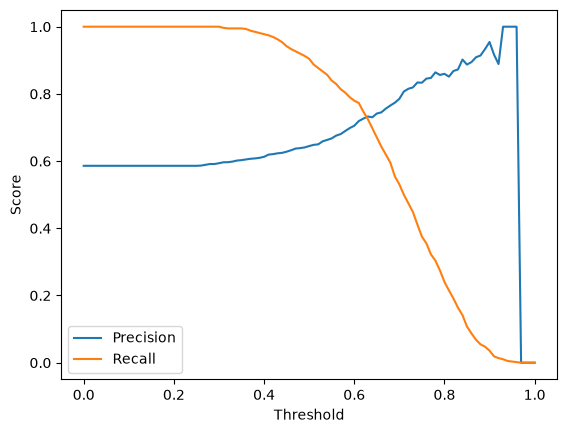

In [18]:
#Creating DataFrame and plotting
df_scores = pd.DataFrame(
    scores,
    columns=['threshold', 'precision', 'recall']
)

plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')

plt.legend()
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.show()

***Finding the intersection***

In [19]:
#Computing the absolute difference between precision and recall
df_scores['diff'] = (
    df_scores['precision'] - df_scores['recall']
).abs()

In [20]:
#Ignoring thresholds where both precision and recall are zero
df_valid = df_scores[
    ~(
        (df_scores.precision == 0) &
        (df_scores.recall == 0)
    )
]

In [21]:
#Finding the threshold with the smallest difference
best = df_valid.loc[df_valid['diff'].idxmin()]

print(best[['threshold', 'precision', 'recall', 'diff']])

threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
Name: 63, dtype: float64


### Question 4

***F1 score***

In [22]:
#Computing F1 for all thresholds from 0.0 to 1.0 with increment 0.01

thresholds = np.arange(0.0, 1.01, 0.01)

scores = []

for t in thresholds:
    y_pred_t = (y_pred >= t).astype(int)

    p = precision_score(y_val, y_pred_t, zero_division=0)
    r = recall_score(y_val, y_pred_t, zero_division=0)

    if p + r == 0:
        f1 = 0
    else:
        f1 = 2 * p * r / (p + r)

    scores.append((t, p, r, f1))

In [23]:
#Creating dataframe
df_scores = pd.DataFrame(
    scores,
    columns=['threshold', 'precision', 'recall', 'f1']
)

df_scores.sort_values('f1', ascending=False).head()

,threshold,precision,recall,f1
41,0.41,0.619306,0.974403,0.757294
42,0.42,0.620765,0.969283,0.756829
43,0.43,0.623204,0.962457,0.756539
47,0.47,0.637324,0.926621,0.755216
44,0.44,0.624581,0.953925,0.754895
